# Exploration of GlobalMart's Sales Data, 2012-2016

## Loading Python Libraries & Dataset CSV file

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('C:/Users/Alexander Benjamin/Desktop/IToL Data Analysis Training/Portfolio/Python for Data Analysis Level 1/Project 1 - GlobalMart/Global_Superstore.csv')

## Initial Data Exploration

What does the data look like? Exploring with .head(), .shape, .info()

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,40098,CA-2014-AB10015140-41954,11/11/2014,11/13/2014,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,TEC-PH-5816,Technology,Phones,Samsung Convoy 3,221.98,2,0.0,62.15,40.77,High
1,26341,IN-2014-JR162107-41675,2/5/2014,2/7/2014,Second Class,JR-162107,Justin Ritter,Corporate,NaN,Wollongong,...,FUR-CH-5379,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.40,9,0.1,-288.77,923.63,Critical
2,25330,IN-2014-CR127307-41929,10/17/2014,10/18/2014,First Class,CR-127307,Craig Reiter,Consumer,NaN,Brisbane,...,TEC-PH-5356,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.17,9,0.1,919.97,915.49,Medium
3,13524,ES-2014-KM1637548-41667,1/28/2014,1/30/2014,First Class,KM-1637548,Katherine Murray,Home Office,NaN,Berlin,...,TEC-PH-5267,Technology,Phones,"Motorola Smart Phone, Cordless",2892.51,5,0.1,-96.54,910.16,Medium
4,47221,SG-2014-RH9495111-41948,11/5/2014,11/6/2014,Same Day,RH-9495111,Rick Hansen,Consumer,NaN,Dakar,...,TEC-CO-6011,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.96,8,0.0,311.52,903.04,Critical


In [5]:
df.shape

(1000, 24)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          1000 non-null   int64  
 1   Order ID        1000 non-null   object 
 2   Order Date      1000 non-null   object 
 3   Ship Date       1000 non-null   object 
 4   Ship Mode       1000 non-null   object 
 5   Customer ID     1000 non-null   object 
 6   Customer Name   1000 non-null   object 
 7   Segment         1000 non-null   object 
 8   Postal Code     194 non-null    float64
 9   City            1000 non-null   object 
 10  State           1000 non-null   object 
 11  Country         1000 non-null   object 
 12  Region          1000 non-null   object 
 13  Market          1000 non-null   object 
 14  Product ID      1000 non-null   object 
 15  Category        1000 non-null   object 
 16  Sub-Category    1000 non-null   object 
 17  Product Name    1000 non-null   ob

## Data Cleaning

Correcting data types, checking for null values and addressing them.

In [7]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          1000 non-null   int64         
 1   Order ID        1000 non-null   object        
 2   Order Date      1000 non-null   datetime64[ns]
 3   Ship Date       1000 non-null   datetime64[ns]
 4   Ship Mode       1000 non-null   object        
 5   Customer ID     1000 non-null   object        
 6   Customer Name   1000 non-null   object        
 7   Segment         1000 non-null   object        
 8   Postal Code     194 non-null    float64       
 9   City            1000 non-null   object        
 10  State           1000 non-null   object        
 11  Country         1000 non-null   object        
 12  Region          1000 non-null   object        
 13  Market          1000 non-null   object        
 14  Product ID      1000 non-null   object        
 15  Categ

In [8]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,1000.000000,1000,1000,194.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,25079.328000,2014-05-30 00:56:09.600000,2014-06-02 01:29:16.799999744,53966.170103,1710.971470,5.55800,0.092840,288.920440,272.384897
min,58.000000,2012-01-08 00:00:00,2012-01-11 00:00:00,2920.000000,1.910000,1.00000,0.000000,-3059.820000,1.070000
25%,15118.750000,2013-06-25 00:00:00,2013-07-01 00:00:00,19134.000000,826.907500,4.00000,0.000000,10.037500,209.827500
50%,25084.500000,2014-07-25 12:00:00,2014-07-30 00:00:00,60564.000000,1585.115000,5.00000,0.000000,190.685000,258.897500
75%,34524.000000,2015-06-10 00:00:00,2015-06-12 00:00:00,88187.500000,2477.812500,7.00000,0.150000,518.872500,351.070250
max,51284.000000,2015-12-31 00:00:00,2016-01-03 00:00:00,98198.000000,9892.740000,14.00000,0.800000,4946.370000,923.630000
std,12897.726632,NaN,NaN,33734.306466,1259.239238,2.71846,0.148666,574.504782,176.160716


In [9]:
df.isnull()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
997,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False


In [10]:
filtered_rows = df[(df['Postal Code'].isnull() | (df['Postal Code'] == '')) & 
                   (df['Country'] == 'United States')]

# Display the filtered results
print(filtered_rows)

# Optional: To see just the count of such rows
print(f"Number of rows with blank/null Postal Code in United States: {len(filtered_rows)}")

Empty DataFrame
Columns: [Row ID, Order ID, Order Date, Ship Date, Ship Mode, Customer ID, Customer Name, Segment, Postal Code, City, State, Country, Region, Market, Product ID, Category, Sub-Category, Product Name, Sales, Quantity, Discount, Profit, Shipping Cost, Order Priority]
Index: []

[0 rows x 24 columns]
Number of rows with blank/null Postal Code in United States: 0


In [11]:
df.isnull().sum()

Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Postal Code       806
City                0
State               0
Country             0
Region              0
Market              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Shipping Cost       0
Order Priority      0
dtype: int64

In [12]:
#checking for null Postal Codes for orders in the US:

filtered_rows = df[(df['Postal Code'].isnull()) & 
                   (df['Country'] == 'United States')]

# Display the count of such rows
print(f"Number of rows with null Postal Code in United States: {len(filtered_rows)}")

#Checking for null Postal Codes for orders in the UK
filtered_rows = df[(df['Postal Code'].isnull()) & 
                   (df['Country'] == 'United Kingdom')]

# Display the count of such rows
print(f"Number of rows with null Postal Code in United Kingdom: {len(filtered_rows)}")

#Comparing this count to total orders for the UK:
filtered_rows = df[df['Country'] == 'United Kingdom']
print(f"Number of rows with Country as United Kingdom: {len(filtered_rows)}")

Number of rows with null Postal Code in United States: 0
Number of rows with null Postal Code in United Kingdom: 39
Number of rows with Country as United Kingdom: 39


In [13]:
#dropping Postal Code, as it is no longer relevant and contains mostly null values
df.drop('Postal Code', axis=1, inplace=True)

#confirming that the field has been dropped, and that there are no more null values
df.head()
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
City              0
State             0
Country           0
Region            0
Market            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Shipping Cost     0
Order Priority    0
dtype: int64

## Exploring the Data

Overall Totals, Top 10 Sellers, Regions Ordered by Value (Sales and Profit)

In [14]:
#calculate total sales for the global dataset
total_sales_np = np.sum(df['Sales'])
print(f'Total Sales:',total_sales_np)

#calculate total profit for the global dataset
total_profit_np = np.sum(df['Profit'])
print(f'Total Profit:',total_profit_np)

#calculate sales/profit correlation
correlation = df['Sales'].corr(df['Profit'])
print(f"Correlation between Sales and Profit: {correlation}")



Total Sales: 1710971.47
Total Profit: 288920.44000000006
Correlation between Sales and Profit: 0.5336756228051001


In [15]:
#top 10 products by Sales Value


top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product Name
Motorola Smart Phone, Full Size                             48542.52
Apple Smart Phone, Full Size                                42303.44
Cisco Smart Phone, Full Size                                41325.20
Nokia Smart Phone, Full Size                                27661.97
Samsung Smart Phone, Cordless                               25438.59
Hoover Stove, Red                                           23477.81
Motorola Smart Phone, with Caller ID                        23239.44
Harbour Creations Executive Leather Armchair, Adjustable    22145.80
Cisco Smart Phone, with Caller ID                           22047.89
Cisco Smart Phone, Cordless                                 21954.87
Name: Sales, dtype: float64


In [25]:
#top 10 products by Profit


top_products_prof = df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10)
print(top_products_prof)

Product Name
Motorola Smart Phone, Full Size                             13088.28
Hoover Stove, Red                                           10288.61
Cisco Smart Phone, Full Size                                 9662.99
Cisco Smart Phone, with Caller ID                            6607.40
Nokia Smart Phone, Full Size                                 5765.12
Harbour Creations Executive Leather Armchair, Adjustable     5552.68
Sauder Classic Bookcase, Traditional                         5285.30
Nokia Smart Phone, Cordless                                  5131.13
GBC Ibimaster 500 Manual ProClick Binding System             4946.37
Safco Classic Bookcase, Metal                                4904.94
Name: Profit, dtype: float64


In [16]:
#Sales by region, ordered

sales_by_region = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
print(sales_by_region)

Region
Western Europe       259576.28
Oceania              220809.08
Southern Asia        205466.26
Eastern Asia         193590.60
Southeastern Asia    147337.60
Central America      140966.21
Northern Europe      103888.63
Southern Europe       94441.11
South America         64550.54
Eastern Europe        45662.19
Central Africa        33810.48
Western Asia          33308.21
Caribbean             30746.74
North Africa          26266.44
Southern Africa       22262.28
Eastern Africa        17387.94
Central US            17187.94
Western US            16729.95
Western Africa        15478.79
Eastern US            12256.44
Southern US            8360.75
Canada                  887.01
Name: Sales, dtype: float64


In [17]:
#Profit by region, ordered

profit_by_region = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)
print(profit_by_region)

Region
Eastern Asia         37911.16
Southern Asia        37536.60
Oceania              33777.56
Western Europe       32783.40
Northern Europe      23552.73
Central America      21741.95
Southern Europe      20557.50
Eastern Europe       12228.45
Southeastern Asia    10561.80
Central Africa        9668.22
South America         7723.58
North Africa          7416.42
Central US            5676.02
Caribbean             5463.82
Western Asia          5262.35
Southern Africa       4876.32
Eastern Africa        4302.72
Eastern US            2544.89
Western US            2458.34
Southern US           1384.72
Western Africa        1278.17
Canada                 213.72
Name: Profit, dtype: float64


## Breakdown by Product Category

Totals and averages for each product category (Technology, Furniture, Office Supplies), measuring Sales, Quantity, and Profit.

Total Technology Sale Value: 
756983.02
Total Furniture Sale Value: 
601492.31
Total Office Supplies Sale Value: 
352496.14
Average Technology Sale Value: 
1916.4127088607595
Average Furniture Sale Value: 
1845.0684355828223
Average Office Supplies Sale Value: 
1263.4270250896059


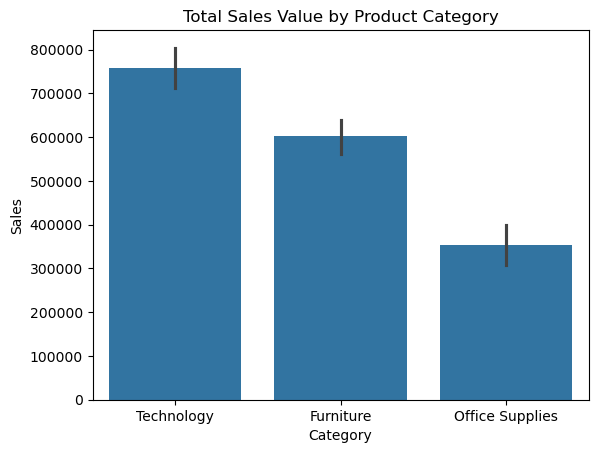

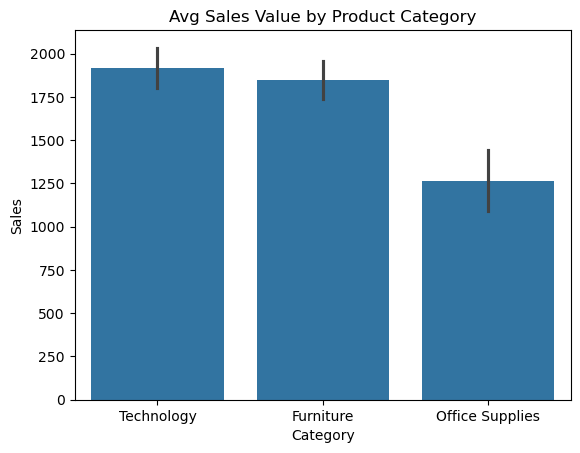

In [18]:

#calculate total sales value for each product category

total_tech_sales = df[df['Category']=='Technology']['Sales'].sum()
print(f"Total Technology Sale Value: \n{total_tech_sales}")

total_furn_sales = df[df['Category']=='Furniture']['Sales'].sum()
print(f"Total Furniture Sale Value: \n{total_furn_sales}")

total_OS_sales = df[df['Category']=='Office Supplies']['Sales'].sum()
print(f"Total Office Supplies Sale Value: \n{total_OS_sales}")

#calculate average sales value for each product category
avg_tech_sales = df[df['Category']=='Technology']['Sales'].mean()
print(f"Average Technology Sale Value: \n{avg_tech_sales}")

avg_furn_sales = df[df['Category']=='Furniture']['Sales'].mean()
print(f"Average Furniture Sale Value: \n{avg_furn_sales}")

avg_OS_sales = df[df['Category']=='Office Supplies']['Sales'].mean()
print(f"Average Office Supplies Sale Value: \n{avg_OS_sales}")

sns.barplot(x='Category', y='Sales', data=df, estimator=sum)
plt.title('Total Sales Value by Product Category')
plt.show()
sns.barplot(x='Category', y='Sales', data=df)
plt.title('Avg Sales Value by Product Category')
plt.show()


Total Technology Sale Qty: 
2321
Total Furniture Sale Qty: 
1782
Total Office Supplies Sale Qty: 
1455
Avg Technology Sale Qty: 
5.875949367088608
Avg Furniture Sale Qty: 
5.466257668711656
Avg Office Supplies Sale Qty: 
5.21505376344086


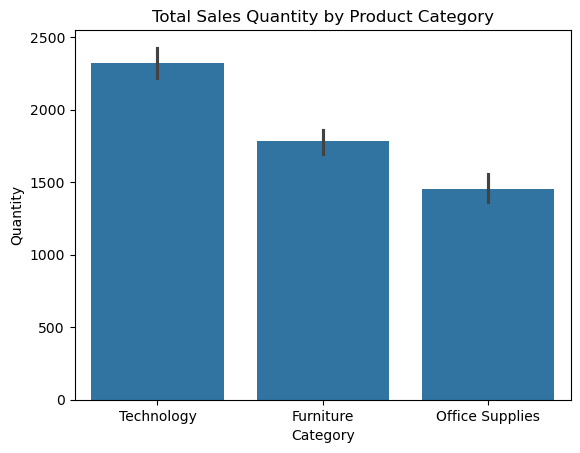

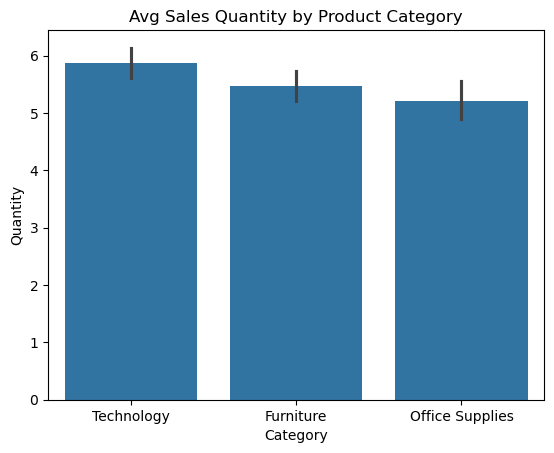

In [19]:
#calculate total sales quantity for each product category

total_tech_qty = df[df['Category']=='Technology']['Quantity'].sum()
print(f"Total Technology Sale Qty: \n{total_tech_qty}")

total_furn_qty = df[df['Category']=='Furniture']['Quantity'].sum()
print(f"Total Furniture Sale Qty: \n{total_furn_qty}")

total_OS_qty = df[df['Category']=='Office Supplies']['Quantity'].sum()
print(f"Total Office Supplies Sale Qty: \n{total_OS_qty}")

#calculate avg sales quantity for each product category

avg_tech_qty = df[df['Category']=='Technology']['Quantity'].mean()
print(f"Avg Technology Sale Qty: \n{avg_tech_qty}")

avg_furn_qty = df[df['Category']=='Furniture']['Quantity'].mean()
print(f"Avg Furniture Sale Qty: \n{avg_furn_qty}")

avg_OS_qty = df[df['Category']=='Office Supplies']['Quantity'].mean()
print(f"Avg Office Supplies Sale Qty: \n{avg_OS_qty}")

sns.barplot(x='Category', y='Quantity', data=df, estimator=sum)
plt.title('Total Sales Quantity by Product Category')
plt.show()
sns.barplot(x='Category', y='Quantity', data=df)
plt.title('Avg Sales Quantity by Product Category')
plt.show()

Total Technology Sale Profit: 
145068.68
Total Furniture Sale Profit: 
82188.95
Total Office Supplies Sale Profit: 
61662.81
Avg Technology Sale Profit: 
367.2624810126582
Avg Furniture Sale Profit: 
252.1133435582822
Avg Office Supplies Sale Profit: 
221.01365591397848


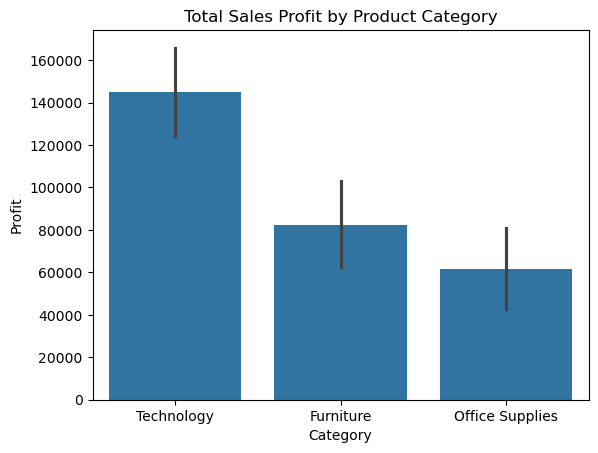

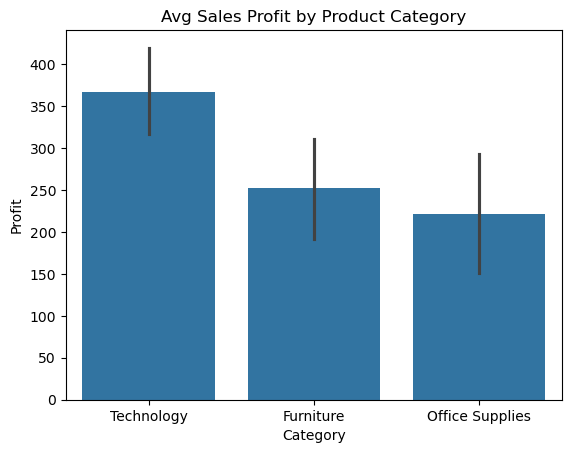

In [20]:
#calculate total sales profit for each product category

total_tech_prf = df[df['Category']=='Technology']['Profit'].sum()
print(f"Total Technology Sale Profit: \n{total_tech_prf}")

total_furn_prf = df[df['Category']=='Furniture']['Profit'].sum()
print(f"Total Furniture Sale Profit: \n{total_furn_prf}")

total_OS_prf = df[df['Category']=='Office Supplies']['Profit'].sum()
print(f"Total Office Supplies Sale Profit: \n{total_OS_prf}")

#calculate avg sales profit for each product category

avg_tech_prf = df[df['Category']=='Technology']['Profit'].mean()
print(f"Avg Technology Sale Profit: \n{avg_tech_prf}")

avg_furn_prf = df[df['Category']=='Furniture']['Profit'].mean()
print(f"Avg Furniture Sale Profit: \n{avg_furn_prf}")

avg_OS_prf = df[df['Category']=='Office Supplies']['Profit'].mean()
print(f"Avg Office Supplies Sale Profit: \n{avg_OS_prf}")


sns.barplot(x='Category', y='Profit', data=df, estimator=sum)
plt.title('Total Sales Profit by Product Category')
plt.show()
sns.barplot(x='Category', y='Profit', data=df)
plt.title('Avg Sales Profit by Product Category')
plt.show()

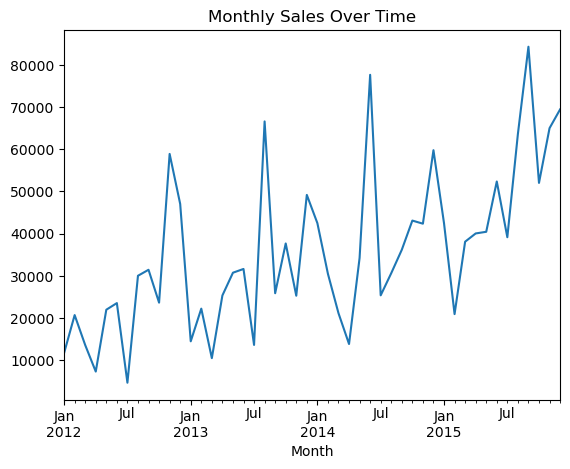

In [21]:
#Create new 'Month' column from Order Date in order to enable time-series analysis
df['Month']= df['Order Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Sales'].sum()
#ensure index is in datetime format for plotting
monthly_sales.index = monthly_sales.index.to_timestamp()

#Plot monthly sales over time
monthly_sales.plot(kind='line')
plt.title('Monthly Sales Over Time')
plt.show()

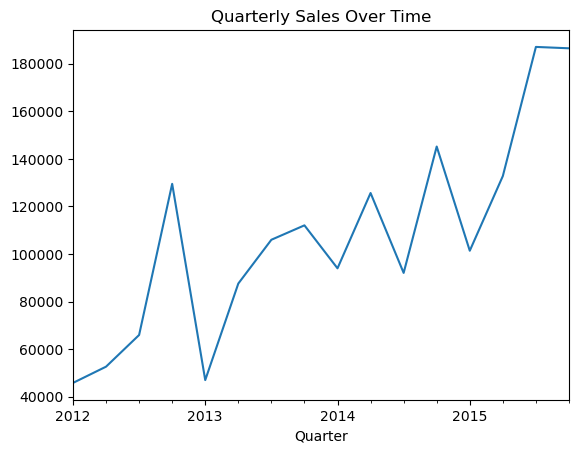

In [22]:
#Create new 'Quarter' column from Order Date in order to enable time-series analysis
df['Quarter']= df['Order Date'].dt.to_period('Q')
quarterly_sales = df.groupby('Quarter')['Sales'].sum()
#ensure index is in datetime format for plotting
quarterly_sales.index = quarterly_sales.index.to_timestamp()

#Plot monthly sales over time
quarterly_sales.plot(kind='line')
plt.title('Quarterly Sales Over Time')
plt.show()

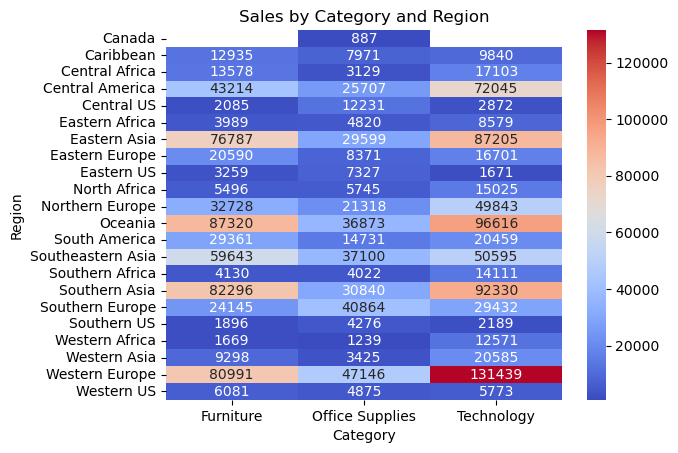

In [24]:
#create pivot table for Sales by Region and Product Category
pivot_table = df.pivot_table(values='Sales', index = 'Region', columns='Category', aggfunc='sum')

#Create a Sales by Region & Product Category heatmap, to show where the most profitable regions are and what product category is performing the best in those places at a glance

sns.heatmap(pivot_table,annot=True, fmt='.0f',cmap='coolwarm')
plt.title('Sales by Category and Region')
plt.show()


## Notable Points From the Heatmap:

Western Europe's Technology sales is the strongest-performing segment in the dataset, followed by Technology sales in Oceania and Southern Asia, Furniture sales in Oceania, and Technology sales in Eastern Asia.

Office Supplies as a category lags behind the other two; its strongest showing is in Western Europe, with 47,146 in sales value. There are, however, a handful of markets where Office Supplies is the best-performing product category:  Southern Europe, and Central, Eastern, and Southern US. Further investigation may provide insight into these markets - a tailored approach may prove useful here, focusing on the relevant strengths 

The least valuable market overall is Canada, where a small amount of sales in Office Supplies is the only recorded sales value. Further investigation might reveal why the Canadian market is so low in value - this could perhaps be due to underserved marketing, strong competition, low physical and digital presence, lateness of entry to market or logistical issues, among other factors.


## Key Findings and Conclusions:

Globally, Technology is the strongest-performing product category, boasting strong sales in regions like Western Europe, Oceania, and Southern and Eastern Asia. It leads the other two categories by volume of units sold, total revenue and profit generated.

Furniture is the second-strongest category, and even leads Technology with a slightly higher average sale value per unit sold.

Office Supplies follows, though the profit generated on a per-unit basis is close between it and Furniture overall.

Generally, the regional markets follow this trend, with some slight variation - for example, Furniture leads Technology in the Caribbean market, and Office Supplies has a small lead on Furniture in Eastern Africa.

However, the data suggests some of the regional markets buck the global trend significantly. The US market, for example, shows a reversed set of conclusions, with Office Supplies as the clear standout, and Furniture and Technology sales trailing in 2nd and 3rd position respectively. Canada, the least valuable regional market by sales, shows no sales for Furniture or Technology at all; further investigation might reveal weaknesses in the strategic approach used in this regional market, or alternative needs which GlobalMart is not currently meeting.

This leads to the following conclusions:

1) Continue to focus on Technology as the greatest-performing product category; leveraging this strength can help GlobalMart continue to grow in most markets. 

2) More in-depth regional market analysis may reveal why certain regions buck the global trend, and why others underperform; operations in these markets can be tailored or scaled as appropriate.
